# 02 Análise de um experimento fatorial $2^2r$

## Configurar workers e cache para reduzir a latência

O objetivo é medir como o número de workers e o uso de cache alteram a latência média de um serviço. O experimento combina dois fatores com dois níveis e seis sessões independentes por combinação. São 24 unidades experimentais.

Seguiremos a sequência dos dados ao modelo, à alocação da variação e à inferência. A análise dos resíduos examinará as condições necessárias para interpretar os testes e os intervalos. Os dados são sintéticos e estão integralmente definidos neste notebook.


## 1 Fatores, níveis e hipóteses antes da coleta

| Fator | Nível baixo $-1$ | Nível alto $+1$ | Hipótese operacional |
| --- | --- | --- | --- |
| A | 2 workers | 8 workers | Mais workers podem reduzir o tempo de espera, mas também elevar a disputa por CPU |
| B | Cache desligado | Cache ligado | O cache pode evitar parte do processamento e reduzir a latência |

A hipótese de interação é que o ganho ao aumentar workers depende do cache. Se o cache já eliminar o trabalho que se beneficiaria de paralelismo, o ganho com mais workers pode diminuir.

A resposta é a latência média em milissegundos de uma sessão com 10 mil requisições e concorrência fixa de 16 clientes. Uma redução de pelo menos 5 ms será considerada relevante para operação. O teste de um coeficiente igual a zero responde a uma pergunta estatística diferente dessa meta operacional.


## 2 Protocolo e unidade experimental

Cada sessão começa com um novo processo, reinicialização do estado e aquecimento de 60 segundos. Quando habilitado, o cache segue uma regra fixa de aquecimento. Hardware, versão do serviço, carga e duração da medição permanecem controlados.

Cada sessão fornece uma resposta. As requisições internas compartilham o processo e não são contadas como replicações independentes. As seis sessões de uma combinação também não formam pares com as seis de outra combinação.

A ordem das 24 sessões é sorteada antes da coleta e registrada separadamente da ordem usada nas contas. Adotaremos confiança de 90%, significância de 10% e testes bilaterais para os coeficientes. Essas decisões antecedem a análise.


In [1]:
from pathlib import Path
from itertools import combinations, product
import base64
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

NOME_NOTEBOOK = '02_analise_22r'
CONFIANCA = CONFIDENCE_LEVEL = 0.90
ALPHA = 1-CONFIANCA
BASE = Path.cwd()
if BASE.name == 'notebooks':
    BASE = BASE.parent
FIGURAS = BASE/'figuras'/NOME_NOTEBOOK
TABELAS = BASE/'tabelas'/NOME_NOTEBOOK
FIGURAS.mkdir(parents=True,exist_ok=True)
TABELAS.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({
    'font.family':'serif','font.serif':['STIXGeneral','DejaVu Serif'],
    'mathtext.fontset':'stix','font.size':11,'axes.labelsize':11,
    'xtick.labelsize':9,'ytick.labelsize':9,'legend.fontsize':9,
    'figure.dpi':130,'figure.facecolor':'white','axes.facecolor':'white',
    'axes.spines.top':False,'axes.spines.right':False,'axes.grid':False,
    'axes.linewidth':.8,'lines.linewidth':1.4,'lines.markersize':4.5,
    'pdf.fonttype':42,'ps.fonttype':42,'savefig.facecolor':'white'})
AZUL='#24577A'
LARANJA='#B76532'
VERDE='#44735B'
CINZA='#707070'
CORES=[AZUL,LARANJA,VERDE,CINZA]
pd.set_option('display.max_columns',14)
pd.set_option('display.float_format',lambda x:f'{x:.5g}')

def salvar_figura(fig,nome):
    if any(ax.get_title() or ax.get_title(loc='left') or ax.get_title(loc='right') for ax in fig.axes):
        raise ValueError('A identificação pertence à legenda externa da figura')
    if getattr(fig,'_suptitle',None) is not None:
        raise ValueError('A identificação pertence ao texto')
    w,h=fig.get_size_inches()
    if w>10 or h>10 or w<3 or h<2:
        raise ValueError('Dimensões físicas inadequadas')
    pdf=FIGURAS/f'{nome}.pdf'
    png=FIGURAS/f'{nome}.png'
    fig.savefig(pdf,format='pdf',dpi=600)
    fig.savefig(png,format='png',dpi=180)
    largura=1000 if len(fig.axes)>1 else 820
    display({'image/png':base64.b64encode(png.read_bytes()).decode('ascii')},raw=True,
        metadata={'image/png':{'width':largura,'height':round(largura*h/w)},
                  'fatorial_pdf':str(pdf.relative_to(BASE)),
                  'largura_polegadas':float(w),'altura_polegadas':float(h)})
    plt.close(fig)

def salvar_tabela(tabela,nome,indice=False,colunas_p=None):
    tabela.to_csv(TABELAS/f'{nome}.csv',index=indice)
    copia=tabela.copy()
    if colunas_p:
        for col in colunas_p:
            copia[col]=copia[col].map(lambda p:'' if pd.isna(p) else formatar_p(p))
    display(copia)

def formatar_p(p):
    return '< 1e-300' if p<=0 else f'{p:.4g}'

def decisao_teste(nome,p,contra,sem_evidencia):
    if not np.isfinite(p):
        display(Markdown(f'**{nome}**\n\nO valor-p não está definido para estes dados. A decisão depende do gráfico e das condições do diagnóstico.'))
        return
    if p<=ALPHA:
        texto=f'É significativo porque o valor-p {formatar_p(p)} é menor ou igual a {ALPHA:.2f}. {contra}'
    else:
        texto=f'Não é significativo porque o valor-p {formatar_p(p)} é maior que {ALPHA:.2f}. {sem_evidencia}'
    display(Markdown(f'**{nome}**\n\n{texto}'))

def matriz_sinais(k):
    if not isinstance(k,(int,np.integer)) or not 1<=k<=8:
        raise ValueError('Use entre um e oito fatores no fatorial completo')
    g=2**k
    niveis=2*((np.arange(g)[:,None]>>np.arange(k))&1)-1
    letras=[chr(65+i) for i in range(k)]
    termos=[]
    colunas=[]
    for mascara in range(g):
        ids=[j for j in range(k) if mascara&(1<<j)]
        termos.append(''.join(letras[j] for j in ids) if ids else '0')
        colunas.append(np.prod(niveis[:,ids],axis=1) if ids else np.ones(g))
    return niveis,np.column_stack(colunas),termos

def ajustar(response):
    response=np.asarray(response,dtype=float)
    if response.ndim!=2 or response.shape[0]<2:
        raise ValueError('Use uma matriz com combinações nas linhas e replicações nas colunas')
    g,r=response.shape
    k=int(np.log2(g))
    if 2**k!=g or r<2 or not np.isfinite(response).all():
        raise ValueError('O desenho completo exige 2**k combinações e pelo menos duas replicações finitas')
    niveis,Xc,termos=matriz_sinais(k)
    N=response.size
    nu=g*(r-1)
    medias=response.mean(axis=1)
    q=Xc.T@medias/g
    X=np.repeat(Xc,r,axis=0)
    y=response.ravel()
    ajustados=X@q
    residuos=y-ajustados
    SSE=float(residuos@residuos)
    SST=float(np.sum((y-y.mean())**2))
    MSE=SSE/nu
    if MSE<=np.finfo(float).eps*max(1,float(np.mean(y*y))):
        raise ValueError('O erro puro é nulo ou numericamente desprezível')
    SS=N*q[1:]**2
    se=np.sqrt(MSE)
    sq=se/np.sqrt(N)
    t=q[1:]/sq
    pval=2*stats.t.sf(np.abs(t),nu)
    crit=stats.t.ppf(1-ALPHA/2,nu)
    efeitos=pd.DataFrame({'Termo':termos[1:],'q':q[1:],'EP de q':sq,
        'IC inferior':q[1:]-crit*sq,'IC superior':q[1:]+crit*sq,
        'Efeito 2q':2*q[1:],'t':t,'Valor-p':pval,
        'Significativo':np.where(pval<=ALPHA,'Sim','Não')})
    anova=pd.DataFrame({'Fonte':termos[1:]+['Erro','Total'],
        'SS':np.r_[SS,SSE,SST],'gl':np.r_[np.ones(g-1,dtype=int),nu,N-1],
        'MS':np.r_[SS,MSE,np.nan],'F':np.r_[SS/MSE,np.nan,np.nan],
        'Valor-p':np.r_[pval,np.nan,np.nan]})
    F_global=float(np.sum(SS)/(g-1)/MSE)
    p_global=float(stats.f.sf(F_global,g-1,nu))
    assert np.isclose(SST,SS.sum()+SSE)
    assert np.allclose(Xc.T@Xc,g*np.eye(g))
    assert np.allclose(SS/MSE,t*t)
    return dict(response=response,k=k,g=g,r=r,N=N,nu=nu,Xc=Xc,X=X,niveis=niveis,
        termos=termos,q=q,y=y,medias=medias,ajustados=ajustados,residuos=residuos,
        SSE=SSE,SST=SST,SS=SS,MSE=MSE,se=se,sq=sq,anova=anova,efeitos=efeitos,
        F_global=F_global,p_global=p_global)

def modelo_escrito(res,nomes=None,resposta='y'):
    partes=[f'{res["q"][0]:.4g}']
    for termo,valor in zip(res['termos'][1:],res['q'][1:]):
        produto=''.join('x_{'+letra+'}' for letra in termo)
        partes.append((' + ' if valor>=0 else ' - ')+f'{abs(valor):.4g}'+produto)
    display(Markdown('$$\\widehat{'+resposta+'}='+''.join(partes)+'.$$'))

def mostrar_resultados(res):
    salvar_tabela(res['efeitos'],'efeitos_ic_testes',colunas_p=['Valor-p'])
    for termo,p in zip(res['termos'][1:],res['efeitos']['Valor-p']):
        decisao_teste(f'Efeito q{termo}',p,
            f'Há evidência de que q{termo} difere de zero nas condições do modelo.',
            f'Não há evidência suficiente de que q{termo} difere de zero. Isso não demonstra ausência de efeito.')

def mostrar_anova(res):
    salvar_tabela(res['anova'],'anova',colunas_p=['Valor-p'])
    tabela=pd.DataFrame([{'F global':res['F_global'],'gl numerador':res['g']-1,
        'gl denominador':res['nu'],'Valor-p':res['p_global']}])
    salvar_tabela(tabela,'F_global',colunas_p=['Valor-p'])
    decisao_teste('Teste F global',res['p_global'],
        'Há evidência de que pelo menos um termo do modelo difere de zero.',
        'Não há evidência suficiente de diferença entre as médias das combinações.')

def graficos_efeitos(res,prefixo):
    fig,ax=plt.subplots(figsize=(5,3),layout='constrained')
    ids=np.arange(res['g']-1)
    margem=stats.t.ppf(1-ALPHA/2,res['nu'])*res['sq']
    ax.errorbar(res['q'][1:],ids,xerr=margem,fmt='o',capsize=3,color=AZUL)
    ax.axvline(0,color=CINZA,lw=.8)
    ax.set_yticks(ids,['q'+t for t in res['termos'][1:]])
    ax.set_xlabel('Coeficiente q e IC de 90% ('+res.get('unidade','u.r.')+')')
    ax.set_ylabel('Termo')
    salvar_figura(fig,prefixo+'_efeitos')

def grafico_variacao(res,prefixo):
    nomes=res['termos'][1:]+['Erro']
    percent=100*np.r_[res['SS'],res['SSE']]/res['SST']
    tabela=pd.DataFrame({'Fonte':nomes,'SS':np.r_[res['SS'],res['SSE']],
                        'Variação alocada (%)':percent})
    salvar_tabela(tabela,prefixo+'_variacao')
    fig,ax=plt.subplots(figsize=(5,3),layout='constrained')
    ordem=np.argsort(percent)
    ax.barh(np.asarray(nomes)[ordem],percent[ordem],color=[CINZA if nomes[i]=='Erro' else AZUL for i in ordem])
    ax.set_xlabel('Variação total alocada (%)')
    ax.set_ylabel('Fonte')
    salvar_figura(fig,prefixo+'_variacao')

def graficos_niveis(res,nomes,niveis_reais,prefixo,com_ic=True):
    k=res['k']
    cols=min(2,k)
    rows=int(np.ceil(k/cols))
    tamanho=(5,3) if rows==1 else (5,5)
    fig,axes=plt.subplots(rows,cols,figsize=tamanho,squeeze=False,layout='constrained')
    ep=res['se']/np.sqrt(res['N']/2)
    margem=stats.t.ppf(1-ALPHA/2,res['nu'])*ep
    for j,ax in enumerate(axes.ravel()):
        if j>=k:
            ax.set_visible(False)
            continue
        vals=[res['medias'][res['niveis'][:,j]==a].mean() for a in [-1,1]]
        if com_ic:ax.errorbar([0,1],vals,yerr=margem,fmt='o-',capsize=3,color=AZUL)
        else:ax.plot([0,1],vals,'o-',color=AZUL)
        ax.set_xticks([0,1],niveis_reais[j])
        ax.set_xlabel(nomes[j])
        ax.set_ylabel('Média ('+res.get('unidade','u.r.')+')'+(' e IC de 90%' if com_ic else ''))
        ax.text(.01,1.025,f'({chr(97+j)})',transform=ax.transAxes,ha='left',va='bottom')
        ax.margins(x=.15)
    salvar_figura(fig,prefixo+'_niveis')

def graficos_interacoes(res,nomes,niveis_reais,prefixo,com_ic=True):
    k=res['k']
    paineis=[]
    if k==1:return
    for a,b in combinations(range(k),2):
        outros=[j for j in range(k) if j not in [a,b]]
        for condicao in product([-1,1],repeat=len(outros)):
            paineis.append((a,b,outros,condicao))
    if k==2:paineis.append((1,0,[],()))
    margem=stats.t.ppf(1-ALPHA/2,res['nu'])*res['se']/np.sqrt(res['r'])
    for inicio in range(0,len(paineis),6):
        bloco=paineis[inicio:inicio+6]
        cols=2 if len(bloco)<=4 else 3
        rows=int(np.ceil(len(bloco)/cols))
        tamanho=(5,3) if rows==1 else ((5,5) if cols==2 else (7,5))
        fig,axes=plt.subplots(rows,cols,figsize=tamanho,squeeze=False,layout='constrained')
        mapa=[]
        for t,ax in enumerate(axes.ravel()):
            if t>=len(bloco):
                ax.set_visible(False)
                continue
            a,b,outros,condicao=bloco[t]
            cond=np.ones(res['g'],dtype=bool)
            for j,v in zip(outros,condicao):cond&=res['niveis'][:,j]==v
            for nivel,cor in [(-1,AZUL),(1,LARANJA)]:
                ys=[res['medias'][cond&(res['niveis'][:,a]==x)&(res['niveis'][:,b]==nivel)].mean() for x in [-1,1]]
                rotulo=niveis_reais[b][0 if nivel==-1 else 1]
                if com_ic:ax.errorbar([0,1],ys,yerr=margem,fmt='o-',capsize=2.5,label=rotulo,color=cor)
                else:ax.plot([0,1],ys,'o-',label=rotulo,color=cor)
            letra=chr(97+t)
            ax.text(.01,1.025,f'({letra})',transform=ax.transAxes,ha='left',va='bottom')
            ax.set_xticks([0,1],niveis_reais[a])
            ax.set_xlabel(nomes[a])
            ax.set_ylabel('Média ('+res.get('unidade','u.r.')+')')
            ax.margins(x=.15,y=.16)
            ax.legend(frameon=False,title=nomes[b],fontsize=8,title_fontsize=9)
            fixos=', '.join(f'{nomes[j]} em {niveis_reais[j][0 if v==-1 else 1]}' for j,v in zip(outros,condicao))
            mapa.append(f'({letra}) {nomes[a]} e {nomes[b]}'+(', '+fixos if fixos else ''))
        display(Markdown('Painéis do gráfico. '+'. '.join(mapa)+'.'))
        salvar_figura(fig,prefixo+f'_interacoes_{inicio//6+1}')

def grid_residuos(res,ordem,prefixo):
    ordem=np.asarray(ordem,dtype=int)
    if not np.array_equal(np.sort(ordem),np.arange(res['N'])):
        raise ValueError('A ordem deve conter cada índice de observação uma vez')
    fig,axes=plt.subplots(2,2,figsize=(5,5),layout='constrained')
    ax=axes[0,0]
    ax.scatter(res['ajustados'],res['residuos'],s=17,color=AZUL)
    ax.axhline(0,color=CINZA,lw=.7)
    ax.set_xlabel('Resposta ajustada ('+res.get('unidade','u.r.')+')')
    ax.set_ylabel('Resíduo ('+res.get('unidade','u.r.')+')')
    ax=axes[0,1]
    for i in range(res['g']):
        ax.scatter(i+1+np.linspace(-.13,.13,res['r']),res['residuos'].reshape(res['g'],res['r'])[i],s=17,color=AZUL)
    ax.axhline(0,color=CINZA,lw=.7)
    ax.set_xlabel('Combinação')
    ax.set_ylabel('Resíduo ('+res.get('unidade','u.r.')+')')
    ax.set_xticks(np.arange(1,res['g']+1))
    ax=axes[1,0]
    quantis,observados=stats.probplot(res['residuos']/(res['se']*np.sqrt(1-1/res['r'])),dist='norm',fit=False)
    ax.scatter(quantis,observados,s=17,color=AZUL)
    ax.plot([min(quantis),max(quantis)],[min(quantis),max(quantis)],color=CINZA,lw=.8)
    ax.set_xlabel('Quantil normal teórico')
    ax.set_ylabel('Resíduo em\nescala comparável')
    ax=axes[1,1]
    ax.plot(np.arange(1,res['N']+1),res['residuos'][ordem],'o-',markersize=3,lw=.8,color=AZUL)
    ax.axhline(0,color=CINZA,lw=.7)
    ax.set_xlabel('Ordem de execução')
    ax.set_ylabel('Resíduo ('+res.get('unidade','u.r.')+')')
    for i,ax in enumerate(axes.ravel()):
        ax.text(.01,1.025,f'({chr(97+i)})',transform=ax.transAxes,ha='left',va='bottom')
    salvar_figura(fig,prefixo+'_residuos')

def _estatistica_ks(amostras):
    amostras=np.atleast_2d(amostras)
    n=amostras.shape[1]
    z=(amostras-amostras.mean(axis=1,keepdims=True))/amostras.std(axis=1,ddof=1,keepdims=True)
    F=stats.norm.cdf(np.sort(z,axis=1))
    return np.maximum(np.max(np.arange(1,n+1)/n-F,axis=1),
                      np.max(F-np.arange(n)/n,axis=1))

def diagnosticos(res,ordem,prefixo):
    ordem=np.asarray(ordem,dtype=int)
    if not np.array_equal(np.sort(ordem),np.arange(res['N'])):
        raise ValueError('A ordem deve ser uma permutação dos índices das observações')
    if res['r']==2:
        W_variancia,p_variancia=np.nan,np.nan
    else:
        W_variancia,p_variancia=stats.levene(*res['response'],center='median')
    e=res['residuos']
    W=float(stats.shapiro(e).statistic)
    D=float(_estatistica_ks(e)[0])
    DW=float(np.sum(np.diff(e[ordem])**2)/np.sum(e*e))
    B=4999
    rng=np.random.default_rng(180042)
    erros=rng.normal(size=(B,res['g'],res['r']))
    simulados=(erros-erros.mean(axis=2,keepdims=True)).reshape(B,res['N'])
    Ws=stats.shapiro(simulados,axis=1).statistic
    Ds=_estatistica_ks(simulados)
    DWs=np.sum(np.diff(simulados[:,ordem],axis=1)**2,axis=1)/np.sum(simulados*simulados,axis=1)
    p_W=(1+np.count_nonzero(Ws<=W))/(B+1)
    p_D=(1+np.count_nonzero(Ds>=D))/(B+1)
    p_DW=min(1,2*min((1+np.count_nonzero(DWs<=DW))/(B+1),
                     (1+np.count_nonzero(DWs>=DW))/(B+1)))
    tabela=pd.DataFrame({'Diagnóstico':['Brown e Forsythe','Shapiro e Wilk','Kolmogorov e Smirnov','Durbin e Watson'],
        'Estatística':[W_variancia,W,D,DW],
        'Valor-p':[p_variancia,p_W,p_D,p_DW],
        'Referência':['F aproximada','Normal no mesmo desenho','Normal no mesmo desenho','Normal independente no mesmo desenho']})
    salvar_tabela(tabela,prefixo+'_diagnosticos',colunas_p=['Valor-p'])
    if res['r']==2:
        display(Markdown('Com duas replicações por combinação, os dois desvios absolutos em relação à mediana são iguais. O teste de Brown e Forsythe fica degenerado. A comparação de dispersões deve usar os gráficos e exige mais replicações para esse teste.'))
    decisao_teste('Homocedasticidade',p_variancia,
        'Há evidência contra a igualdade das variâncias.',
        'Não há evidência suficiente contra a igualdade das variâncias.')
    for nome,p in [('Shapiro e Wilk',p_W),('Kolmogorov e Smirnov',p_D)]:
        decisao_teste(nome,p,'Há evidência contra a normalidade dos erros sob a referência adotada.',
            'Não há evidência suficiente contra a normalidade sob a referência adotada.')
    decisao_teste('Durbin e Watson',p_DW,
        'Há evidência de dependência serial na comparação com a referência independente.',
        'Não há evidência suficiente de dependência serial nessa comparação. O protocolo continua necessário.')
    return tabela

def grid_padroes(prefixo):
    rng=np.random.default_rng(180043)
    n=80
    x=np.linspace(-1,1,n)
    iid=rng.normal(0,1,n)
    pos=np.zeros(n)
    neg=np.zeros(n)
    for i in range(1,n):
        pos[i]=.83*pos[i-1]+rng.normal(0,.6)
        neg[i]=-.83*neg[i-1]+rng.normal(0,.6)
    padroes=[iid,pos,neg,2*np.sin(np.linspace(0,5*np.pi,n))+rng.normal(0,.3,n),
        rng.normal(0,np.linspace(.2,2,n)),3*(x*x-x.dot(x)/n)+rng.normal(0,.3,n)]
    fig,axes=plt.subplots(2,3,figsize=(7,5),layout='constrained')
    for i,(ax,e) in enumerate(zip(axes.ravel(),padroes)):
        eixo=np.arange(1,n+1) if i<4 else x
        if i<4:ax.plot(eixo,e,'o-',markersize=2,lw=.7,color=AZUL)
        else:ax.scatter(eixo,e,s=11,color=AZUL)
        ax.axhline(0,color=CINZA,lw=.7)
        ax.set_xlabel('Ordem' if i<4 else 'Valor ajustado')
        ax.set_ylabel('Resíduo ilustrativo')
        ax.text(.01,1.025,f'({chr(97+i)})',transform=ax.transAxes,va='bottom')
    salvar_figura(fig,prefixo+'_padroes')

def graficos_comparacao(resultados,rotulos,prefixo):
    fig,axes=plt.subplots(1,len(resultados),figsize=(5,3) if len(resultados)<=2 else (7,3),
                          squeeze=False,layout='constrained')
    for i,(res,rotulo) in enumerate(zip(resultados,rotulos)):
        ax=axes[0,i]
        margem=stats.t.ppf(1-ALPHA/2,res['nu'])*res['sq']
        ax.errorbar(res['q'][1:],np.arange(res['g']-1),xerr=margem,fmt='o',capsize=3,color=CORES[i%4])
        ax.axvline(0,color=CINZA,lw=.7)
        ax.set_yticks(np.arange(res['g']-1),['q'+t for t in res['termos'][1:]])
        ax.set_xlabel('q e IC de 90% ('+res.get('unidade','u.r.')+')')
        ax.set_ylabel(rotulo)
    salvar_figura(fig,prefixo+'_comparacao')

from pathlib import Path
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats


def _dados_combinacoes(res, nomes, niveis_reais):
    response = np.asarray(res['response'], dtype=float)
    if response.ndim != 2 or response.shape[0] < 2 or response.shape[1] < 2 or not np.isfinite(response).all():
        raise ValueError('Use respostas finitas com ao menos duas replicações por combinação')
    g, r = response.shape
    k = int(np.log2(g))
    if 2**k != g or len(nomes) != k or len(niveis_reais) != k:
        raise ValueError('Os fatores e os níveis devem corresponder ao fatorial completo')
    if len(set(nomes)) != k or any(len(par) != 2 for par in niveis_reais):
        raise ValueError('Use nomes distintos e dois níveis reais por fator')
    niveis = np.asarray(res['niveis'], dtype=int)
    if niveis.shape != (g, k) or not np.isin(niveis, [-1, 1]).all():
        raise ValueError('A matriz de níveis deve acompanhar as linhas da resposta')
    if np.unique(niveis, axis=0).shape[0] != g:
        raise ValueError('As combinações devem aparecer uma vez na matriz de níveis')
    medias = response.mean(axis=1)
    nu = g * (r - 1)
    mse = float(np.sum((response - medias[:, None])**2) / nu)
    if not np.isfinite(mse) or mse < 0:
        raise ValueError('O erro puro precisa produzir uma variância finita')
    if 'MSE' in res and not np.isclose(float(res['MSE']), mse, rtol=1e-9, atol=1e-12):
        raise ValueError('MSE deve ser o erro puro comum do modelo completo')
    ep = np.sqrt(mse / r)
    quantil = float(stats.t.ppf(0.95, nu))
    margem = quantil * ep
    experimentos = [f'Exp{i + 1}' for i in range(g)]
    codigos = [''.join(chr(65 + j) + ('+' if nivel == 1 else '-')
                       for j, nivel in enumerate(linha)) for linha in niveis]
    desenho = pd.DataFrame({'Experimento': experimentos, 'Combinação': codigos})
    for j, nome in enumerate(nomes):
        desenho[nome] = [str(niveis_reais[j][0 if v == -1 else 1]) for v in niveis[:, j]]
    resumo = desenho.copy()
    resumo['Replicações'] = r
    resumo['Média'] = medias
    resumo['MSE comum'] = mse
    resumo['Graus de liberdade'] = nu
    resumo['EP da média'] = ep
    resumo['Quantil t de 90%'] = quantil
    resumo['IC90 inferior'] = medias - margem
    resumo['IC90 superior'] = medias + margem
    rng = np.random.default_rng(180501)
    jitter = np.vstack([rng.permutation(np.linspace(-0.12, 0.12, r)) for _ in range(g)])
    pontos = pd.DataFrame({
        'Experimento': np.repeat(experimentos, r),
        'Combinação': np.repeat(codigos, r),
        'Replicação': np.tile(np.arange(1, r + 1), g),
        'Resposta': response.ravel(),
        'Média do tratamento': np.repeat(medias, r),
        'Deslocamento horizontal': jitter.ravel(),
        'Posição horizontal': (np.arange(g)[:, None] + jitter).ravel()
    })
    return dict(response=response, g=g, r=r, k=k, niveis=niveis, medias=medias,
                nu=nu, mse=mse, ep=ep, margem=margem, jitter=jitter,
                experimentos=experimentos, codigos=codigos, desenho=desenho,
                resumo=resumo, pontos=pontos, unidade=str(res.get('unidade', 'u.r.')))


def _tabela_niveis(ax, dados, nomes):
    ax.set_axis_off()
    linhas = [[textwrap.fill(str(v), width=10, break_long_words=False)
               for v in dados['desenho'][nome]] for nome in nomes]
    tabela = ax.table(cellText=linhas, rowLabels=nomes,
                      colLabels=dados['experimentos'], cellLoc='center',
                      rowLoc='left', loc='center', bbox=[0, 0, 1, 1])
    tabela.auto_set_font_size(False)
    tabela.set_fontsize(8 if dados['g'] <= 4 else 7)
    for (linha, coluna), celula in tabela.get_celld().items():
        celula.set_linewidth(0.45)
        celula.set_edgecolor('#A0A0A0')
        celula.PAD = 0.025
        if linha == 0:
            celula.set_facecolor('#F0F0F0')
        if coluna == -1:
            celula.set_text_props(weight='bold')
    return tabela


def _eixos_combinacoes(dados, nomes, n_paineis, com_tabela, compartilhar_y):
    if n_paineis not in (1, 2):
        raise ValueError('Use um cenário ou dois cenários lado a lado')
    if n_paineis == 1:
        tamanho = (5, 4) if com_tabela else (5, 3)
        if dados['g'] > 8:
            tamanho = (9, 4.5) if com_tabela else (9, 3)
    else:
        tamanho = (7, 4) if com_tabela else (7, 3.5)
    fig = plt.figure(figsize=tamanho, layout='constrained')
    if com_tabela:
        grade = fig.add_gridspec(2, n_paineis, height_ratios=[3.3, 1.1])
    else:
        grade = fig.add_gridspec(1, n_paineis)
    eixos = []
    for i in range(n_paineis):
        eixo = fig.add_subplot(grade[0, i], sharey=eixos[0] if compartilhar_y and i else None)
        eixo.tick_params(axis='both', labelsize=9)
        eixo.tick_params(axis='y', labelleft=True)
        eixos.append(eixo)
    if com_tabela:
        _tabela_niveis(fig.add_subplot(grade[1, :]), dados, nomes)
    return fig, eixos


def _painel_pontos(ax, dados, rotulos_x):
    cores = globals().get('CORES', ['#24577A', '#B76532', '#44735B', '#707070'])
    for i, valores in enumerate(dados['response']):
        ax.scatter(i + dados['jitter'][i], valores, s=24,
                   color=cores[i % len(cores)], alpha=0.80, zorder=3)
        ax.hlines(dados['medias'][i], i - 0.21, i + 0.21, color='black',
                  linewidth=1.8, zorder=5, label='Média do tratamento' if i == 0 else None)
    ax.set_xticks(np.arange(dados['g']), rotulos_x)
    ax.set_xlim(-0.55, dados['g'] - 0.45)
    ax.set_xlabel('Combinação dos fatores')
    ax.set_ylabel(f'Resposta ({dados["unidade"]})')
    ax.margins(y=0.12)
    ax.legend(frameon=False, fontsize=8, loc='best')


def _painel_barras(ax, dados, rotulos_x):
    x = np.arange(dados['g'])
    ax.bar(x, dados['medias'], width=0.62, color='#24577A', alpha=0.84, zorder=2)
    ax.errorbar(x, dados['medias'], yerr=dados['margem'], fmt='none',
                ecolor='black', elinewidth=1.1, capsize=3.0, capthick=1.1, zorder=4)
    for i, media in enumerate(dados['medias']):
        ax.annotate(f'{media:.3g}', xy=(i, media + dados['margem']),
                    xytext=(0, 4), textcoords='offset points', ha='center',
                    va='bottom', fontsize=8, clip_on=False)
    ax.set_xticks(x, rotulos_x)
    ax.set_xlim(-0.55, dados['g'] - 0.45)
    ax.set_xlabel('Combinação dos fatores')
    ax.set_ylabel(f'Média e IC de 90% ({dados["unidade"]})')
    ax.margins(y=0.20)


def _gravar_dados_combinacoes(dados, prefixo, rotulos):
    grupos_pontos, grupos_medias = [], []
    for painel, rotulo in zip(dados, rotulos):
        pontos = painel['pontos'].copy()
        medias = painel['resumo'].copy()
        if len(dados) > 1:
            pontos.insert(0, 'Cenário', rotulo)
            medias.insert(0, 'Cenário', rotulo)
        grupos_pontos.append(pontos)
        grupos_medias.append(medias)
    tabelas = {'observacoes': pd.concat(grupos_pontos, ignore_index=True),
               'medias_ic90': pd.concat(grupos_medias, ignore_index=True),
               'niveis': dados[0]['desenho'].copy()}
    if 'TABELAS' in globals():
        pasta = Path(globals()['TABELAS'])
        pasta.mkdir(parents=True, exist_ok=True)
        for sufixo, tabela in tabelas.items():
            tabela.to_csv(pasta / f'{prefixo}_{sufixo}.csv', index=False)
    return tabelas


def _gerar_graficos_combinacoes(resultados, rotulos, nomes, niveis_reais, prefixo,
                               compartilhar_y, com_tabela):
    dados = [_dados_combinacoes(res, nomes, niveis_reais) for res in resultados]
    if not dados or len(dados) != len(rotulos):
        raise ValueError('Informe um rótulo para cada cenário')
    if any(not painel['desenho'].equals(dados[0]['desenho']) for painel in dados[1:]):
        raise ValueError('Os painéis precisam representar as mesmas combinações')
    if compartilhar_y and len({painel['unidade'] for painel in dados}) > 1:
        raise ValueError('Escalas compartilhadas exigem a mesma unidade da resposta')
    com_tabela = dados[0]['k'] >= 3 if com_tabela is None else bool(com_tabela)
    rotulos_x = dados[0]['experimentos'] if com_tabela else dados[0]['codigos']
    if len(dados) == 2:
        fig = plt.figure(figsize=(7, 6) if com_tabela else (7, 5), layout='constrained')
        grade = fig.add_gridspec(3, 2, height_ratios=[1, 1, 0.48]) if com_tabela else fig.add_gridspec(2, 2)
        for linha, desenhar in enumerate([_painel_pontos, _painel_barras]):
            primeiro = None
            for coluna, painel in enumerate(dados):
                ax = fig.add_subplot(grade[linha, coluna],
                                     sharey=primeiro if compartilhar_y and coluna else None)
                if coluna == 0:
                    primeiro = ax
                desenhar(ax, painel, rotulos_x)
                ax.tick_params(axis='both', labelsize=9)
                ax.tick_params(axis='y', labelleft=True)
                letra = chr(97 + 2 * linha + coluna)
                ax.text(0.01, 1.045, f'({letra})', transform=ax.transAxes,
                        ha='left', va='bottom', fontsize=10)
        if com_tabela:
            _tabela_niveis(fig.add_subplot(grade[2, :]), dados[0], nomes)
        descricoes = [f'Pontos de {rotulos[0]}', f'Pontos de {rotulos[1]}',
                      f'Média e IC de {rotulos[0]}', f'Média e IC de {rotulos[1]}']
        mapa = '. '.join(f'({chr(97 + i)}) {rotulo}' for i, rotulo in enumerate(descricoes))
        display(Markdown('Painéis do gráfico. ' + mapa + '.'))
        salvar_figura(fig, f'{prefixo}_pontos_medias_ic90')
        return _gravar_dados_combinacoes(dados, prefixo, rotulos)
    for tipo, desenhar in [('pontos', _painel_pontos), ('medias_ic90', _painel_barras)]:
        fig, eixos = _eixos_combinacoes(dados[0], nomes, len(dados), com_tabela, compartilhar_y)
        for i, (ax, painel) in enumerate(zip(eixos, dados)):
            desenhar(ax, painel, rotulos_x)
            if len(dados) > 1:
                ax.text(0.01, 1.045, f'({chr(97 + i)})', transform=ax.transAxes,
                        ha='left', va='bottom', fontsize=10)
        if len(dados) > 1:
            mapa = '. '.join(f'({chr(97 + i)}) {rotulo}' for i, rotulo in enumerate(rotulos))
            display(Markdown('Painéis do gráfico. ' + mapa + '.'))
        salvar_figura(fig, f'{prefixo}_{tipo}')
    return _gravar_dados_combinacoes(dados, prefixo, rotulos)


def graficos_combinacoes(res, nomes, niveis_reais, prefixo, *, com_tabela=None):
    """Gera pontos com médias e barras com IC t individual de 90%."""
    return _gerar_graficos_combinacoes([res], [''], nomes, niveis_reais, prefixo,
                                      compartilhar_y=False, com_tabela=com_tabela)


def graficos_combinacoes_pareadas(resultados, rotulos, nomes, niveis_reais, prefixo,
                                 *, compartilhar_y=True, com_tabela=None):
    """Gera um grid 2 por 2 com versões nas colunas e tipos de gráfico nas linhas."""
    if len(resultados) != 2:
        raise ValueError('Informe exatamente dois cenários para os painéis lado a lado')
    return _gerar_graficos_combinacoes(resultados, rotulos, nomes, niveis_reais, prefixo,
                                      compartilhar_y=compartilhar_y, com_tabela=com_tabela)


## 3 Dados sintéticos e ordem de execução

Na geração dos dados, usamos erros normais independentes com desvio padrão de 3,5 ms. As quatro médias populacionais do exemplo são 134, 102, 82 e 82 ms. Esses valores foram escolhidos para representar um benefício de workers que diminui quando o cache está ligado.

As linhas seguem a ordem padrão $A-B-$, $A+B-$, $A-B+$ e $A+B+$. Cada coluna é uma sessão independente. A estimação utilizará as respostas geradas e não os parâmetros conhecidos da simulação.


In [2]:
rng_dados = np.random.default_rng(20261019)
rng_ordem = np.random.default_rng(2202)
r = 6
medias_populacionais = np.array([134.0, 102.0, 82.0, 82.0])
response = medias_populacionais[:, None] + rng_dados.normal(0.0, 3.5, size=(4, r))
res = ajustar(response)
res['unidade'] = 'ms'
ordem = rng_ordem.permutation(res['N'])
nomes = ['Workers', 'Cache']
niveis_reais = [['2 workers', '8 workers'], ['Desligado', 'Ligado']]

observacoes = pd.DataFrame({
    'Sessão': np.arange(1, res['N'] + 1),
    'A': np.repeat(res['niveis'][:, 0], r),
    'B': np.repeat(res['niveis'][:, 1], r),
    'Latência em ms': res['y'],
})
observacoes['Ordem executada'] = np.argsort(ordem) + 1
display(observacoes.round(3))
print(f"Foram {res['g']} combinações com {res['r']} replicações, totalizando {res['N']} sessões.")


,Sessão,A,B,Latência em ms,Ordem executada
0,1,-1,-1,134.22,19
1,2,-1,-1,130.22,23
2,3,-1,-1,135.46,12
3,4,-1,-1,136.29,21
4,5,-1,-1,132.38,20
5,6,-1,-1,130.97,1
6,7,1,-1,100.08,10
7,8,1,-1,104.25,16
8,9,1,-1,102.81,5
9,10,1,-1,103.17,4


Foram 4 combinações com 6 replicações, totalizando 24 sessões.


## 4 Tabela de sinais e coeficientes de Jain

O modelo completo contém o intercepto, os fatores A e B e a interação AB. O sinal da interação é o produto dos sinais dos fatores.

$$y_{ij}=q_0+q_Ax_{Ai}+q_Bx_{Bi}+q_{AB}x_{Ai}x_{Bi}+\varepsilon_{ij}.$$

Para cada termo, multiplicamos sua coluna de sinais pelas médias das combinações, somamos e dividimos por quatro. A ortogonalidade permite escrever

$$\widehat{\boldsymbol q}=\frac{X_c^{\mathsf T}\bar{\boldsymbol y}}{4}.$$

A notação q acompanha Jain. A diferença marginal entre o nível alto e o baixo de um fator é $2q$. Essa diferença faz uma média sobre os níveis do outro fator. O intercepto $q_0$ é a média geral e permanece sem duplicação.


In [3]:
sinais = pd.DataFrame(res['Xc'].astype(int), columns=res['termos'])
sinais.insert(0, 'Combinação', ['A baixo B baixo', 'A alto B baixo',
                             'A baixo B alto', 'A alto B alto'])
sinais['Média em ms'] = res['medias']
display(sinais.round(3))
coeficientes = pd.DataFrame({'Termo': res['termos'], 'q estimado em ms': res['q']})
display(coeficientes.round(4))


,Combinação,0,A,B,AB,Média em ms
0,A baixo B baixo,1,-1,-1,1,133.26
1,A alto B baixo,1,1,-1,-1,103.27
2,A baixo B alto,1,-1,1,-1,83.305
3,A alto B alto,1,1,1,1,83.757


,Termo,q estimado em ms
0,0,100.9
1,A,-7.3839
2,B,-17.366
3,AB,7.6098


## 5 Modelo estimado

Substituímos os coeficientes na equação. A previsão se refere à média da combinação escolhida. Uma sessão individual também contém a flutuação representada pelo erro experimental.

Os sinais de A e B continuam valendo $-1$ e $+1$. Os valores físicos dos níveis aparecem na tabela de fatores. A equação descreve as quatro combinações investigadas.


In [4]:
modelo_escrito(res)


$$\widehat{y}=100.9 - 7.384x_{A} - 17.37x_{B} + 7.61x_{A}x_{B}.$$

### Observações e médias por combinação

Cada ponto representa uma sessão. O pequeno deslocamento horizontal permite enxergar valores próximos e não modifica a resposta. O traço preto indica a média do tratamento. A combinação no eixo horizontal não representa a ordem de execução.

As barras mostram as médias e as hastes mostram ICs individuais de 90%. O erro padrão da média de uma combinação é $\sqrt{MSE/r}$, com $MSE=SSE/[g(r-1)]$ e $g=2^k$. Assim,

$$IC_{90}(\mu_i)=\bar y_i\pm t_{0{,}95,\,g(r-1)}\sqrt{\frac{MSE}{r}}.$$

Usamos t porque a variância dos erros é estimada pelas replicações. Com desvio padrão populacional conhecido, usaríamos z e esse desvio no lugar de $\sqrt{MSE}$. Os ICs pressupõem erros normais independentes com variância comum. Eles expressam a incerteza da média e não a dispersão de uma sessão individual. A sobreposição das hastes não substitui o teste de uma diferença entre médias.


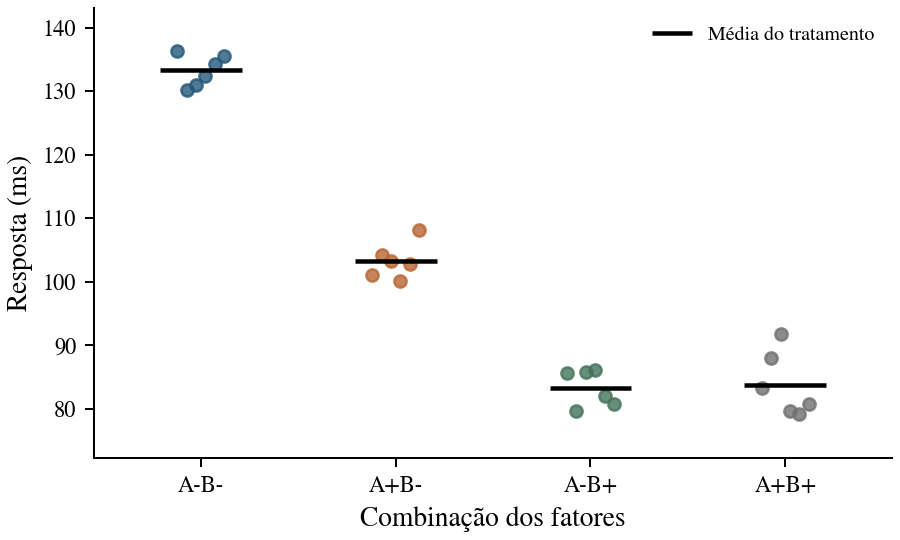

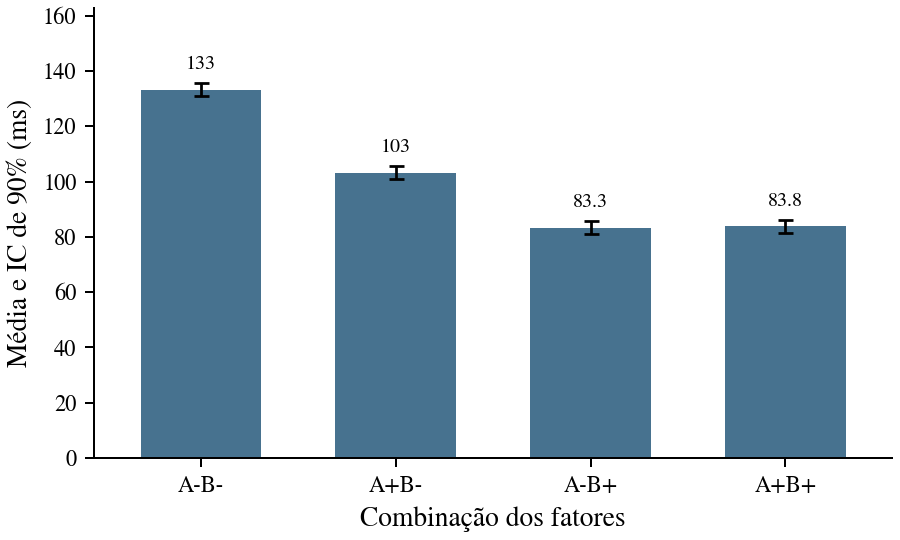

In [5]:
tabela_combinacoes = graficos_combinacoes(res, nomes, niveis_reais, "combinacoes")


## 6 Intervalos e significância

As replicações estimam a variação dentro das combinações. O modelo completo usa quatro parâmetros, portanto

$$\nu=4(r-1)=N-4,\qquad MSE=\frac{SSE}{\nu},\qquad s_e=\sqrt{MSE}.$$

O erro padrão comum dos coeficientes é $s_q=s_e/\sqrt{N}$. Para A, B e AB, as hipóteses são

$$H_0\quad q_S=0,\qquad H_A\quad q_S\ne0.$$

A estatística é $t_S=\widehat q_S/s_q$, com $\nu$ graus de liberdade sob o modelo normal com erros independentes e variância comum. O valor-p bilateral é $2P(T_\nu\ge|t_S|)$.

Rejeitamos $H_0$ quando o valor-p é menor ou igual a $\alpha$. Caso contrário, não a rejeitamos. O valor-p mede a incompatibilidade dos dados com $H_0$ na referência adotada. Ele não é a probabilidade de $H_0$ ser verdadeira.


### Distribuições t e z nos intervalos

As convenções da aula usam $z_{1-\alpha/2}$ para um quantil da normal padrão e $t_{1-\alpha/2,\nu}$ para um quantil de Student. Para uma média de observações normais independentes, usamos z quando o desvio-padrão populacional $\sigma$ é conhecido. Quando $\sigma$ é estimado pela própria amostra, usamos t com os graus de liberdade da estimativa da variância.

No fatorial completo balanceado, $N=2^kr$ e $\nu=2^k(r-1)$. Como $\sigma$ é desconhecido, estimamos $s_e^2=SSE/\nu$ e construímos o IC individual de um coeficiente por

$$\widehat q_S\pm t_{1-\alpha/2,\nu}\frac{s_e}{\sqrt N}.$$

Se $\sigma$ fosse conhecido, substituiríamos $s_e$ por $\sigma$ e o quantil t por z. Para muitos graus de liberdade, t se aproxima de z. Ter mais de 30 observações não torna $\sigma$ conhecido nem exige abandonar t. A interpretação exata dos ICs clássicos pressupõe erros normais independentes com variância comum. Jain fornece a notação q e Montgomery apresenta essa relação com o modelo de regressão.

Os exemplos usam confiança de 90% e $\alpha=0{,}10$. O efeito alto menos baixo do contraste é $2q_S$. Seus dois limites também são multiplicados por dois. Os intervalos apresentados são individuais.


In [6]:
mostrar_resultados(res)


,Termo,q,EP de q,IC inferior,IC superior,Efeito 2q,t,Valor-p,Significativo
0,A,-7.3839,0.7059,-8.6013,-6.1664,-14.768,-10.46,1.477e-09,Sim
1,B,-17.366,0.7059,-18.583,-16.148,-34.731,-24.601,2.007e-16,Sim
2,AB,7.6098,0.7059,6.3924,8.8273,15.22,10.78,8.814e-10,Sim


**Efeito qA**

É significativo porque o valor-p 1.477e-09 é menor ou igual a 0.10. Há evidência de que qA difere de zero nas condições do modelo.

**Efeito qB**

É significativo porque o valor-p 2.007e-16 é menor ou igual a 0.10. Há evidência de que qB difere de zero nas condições do modelo.

**Efeito qAB**

É significativo porque o valor-p 8.814e-10 é menor ou igual a 0.10. Há evidência de que qAB difere de zero nas condições do modelo.

### Como ler a tabela

O coeficiente estima o tamanho e a direção do contraste na escala de Jain. O erro padrão mede a incerteza dessa estimativa. O intervalo individual de 90% é

$$\widehat q_S\pm t_{0{,}95,\nu}s_q.$$

Multiplicar a estimativa e os dois limites por dois fornece o contraste $2q_S$. Um intervalo que inclui zero não demonstra ausência de efeito. Um intervalo que exclui zero sustenta a rejeição do teste bilateral correspondente.

Os intervalos são individuais. Aplicar vários testes no nível de 10% não fornece automaticamente controle global de 10% para todos os resultados. A relevância operacional deve considerar o tamanho da mudança em ms e a meta definida no planejamento.


## 7 Teste global e ANOVA por termo

O teste global compara o modelo completo com uma única média para todas as combinações.

$$H_0\quad q_A=q_B=q_{AB}=0.$$

$$H_A\quad \text{pelo menos um desses coeficientes é diferente de zero}.$$

A estatística é

$$F_{\mathrm{global}}=\frac{(SST-SSE)/3}{MSE},$$

com referência $F_{3,\nu}$ sob $H_0$. Para cada termo, $F_S=SS_S/MSE$ tem referência $F_{1,\nu}$ e coincide com $t_S^2$. O teste global identifica alguma diferença entre as médias, mas não identifica sozinho o termo responsável. A significância do modelo também não valida suas premissas.


### Como ler a ANOVA

A ANOVA organiza a mesma decomposição usada na alocação da variação.

| Coluna | Leitura |
| --- | --- |
| SS ou SQ | Soma de quadrados atribuída ao termo ou ao erro, na unidade da resposta ao quadrado |
| gl | Graus de liberdade usados naquela parcela |
| MS ou QM | Quadrado médio, calculado por SQ dividida por gl |
| F | Razão entre o quadrado médio do termo e o quadrado médio do erro |
| Valor-p | Probabilidade de um F pelo menos tão grande sob a hipótese nula e as condições do modelo |

No fatorial completo balanceado, cada termo possui um grau de liberdade. O erro possui $\nu=2^k(r-1)$ e seu quadrado médio é $MSE=SSE/\nu$. O total possui $N-1$ graus de liberdade. Assim,

$$F_S=\frac{QM_S}{MSE}=\frac{SS_S/1}{SSE/\nu}.$$

As referências são $F_{1,\nu}$ por termo e $F_{2^k-1,\nu}$ para o modelo. A decisão usa as hipóteses já apresentadas. Um valor-p menor ou igual a $\alpha$ leva à rejeição da hipótese correspondente. Um valor maior indica evidência insuficiente para rejeitá-la.

A alocação mostra $100SS_S/SST$. A ANOVA compara cada parcela com a variação entre réplicas por meio do MSE. Por isso, uma parcela pequena de SST ainda pode ser significativa quando o erro é pequeno. O teste não informa sozinho a direção ou a importância prática do efeito. As linhas de erro e total não recebem testes F próprios.


In [7]:
mostrar_anova(res)


,Fonte,SS,gl,MS,F,Valor-p
0,A,1308.5,1,1308.5,109.42,1.477e-09
1,B,7237.6,1,7237.6,605.2,2.007e-16
2,AB,1389.8,1,1389.8,116.22,8.814e-10
3,Erro,239.18,20,11.959,NaN,
4,Total,10175,23,NaN,NaN,


,F global,gl numerador,gl denominador,Valor-p
0,276.94,3,20,1.885e-16


**Teste F global**

É significativo porque o valor-p 1.885e-16 é menor ou igual a 0.10. Há evidência de que pelo menos um termo do modelo difere de zero.

## 8 Alocação da variação

A variação total usa as 24 respostas individuais e sua média geral. O erro puro usa os desvios de cada sessão em relação à média de sua combinação.

$$SST=\sum_{i,j}(y_{ij}-\bar y)^2,\qquad SSE=\sum_{i,j}(y_{ij}-\bar y_i)^2.$$

Neste desenho balanceado, $SS_A=N\widehat q_A^2$, $SS_B=N\widehat q_B^2$ e $SS_{AB}=N\widehat q_{AB}^2$. Assim,

$$SST=SS_A+SS_B+SS_{AB}+SSE.$$

Cada barra mostra $100SS/SST$, incluindo a parcela de erro. A porcentagem descreve a variação observada atribuída a um contraste. Uma parcela de 50% não significa redução da latência em 50%. A interação recebe sua própria parcela.


,Fonte,SS,Variação alocada (%)
0,A,1308.5,12.86
1,B,7237.6,71.13
2,AB,1389.8,13.659
3,Erro,239.18,2.3506


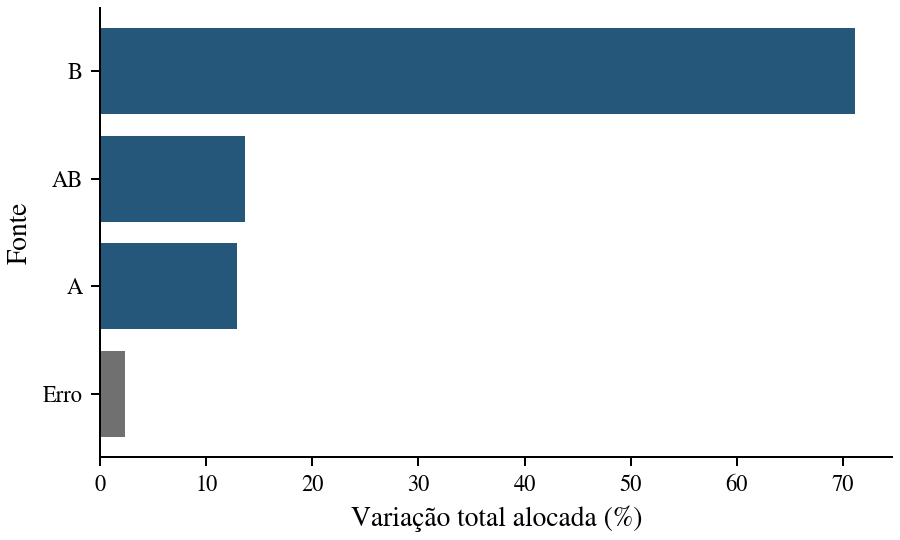

In [8]:
grafico_variacao(res, '01_variacao')


## 9 Direção dos efeitos e níveis dos fatores

A alocação da variação compara magnitudes quadráticas e perde o sinal dos coeficientes. O gráfico dos efeitos recupera direção e incerteza. Para latência, um contraste negativo entre o nível alto e o baixo corresponde a uma redução média.

O gráfico de níveis mostra as médias marginais. Para workers, a média de cada nível inclui as duas condições de cache. Para cache, inclui os dois níveis de workers. As barras indicam intervalos individuais de 90% dessas médias.


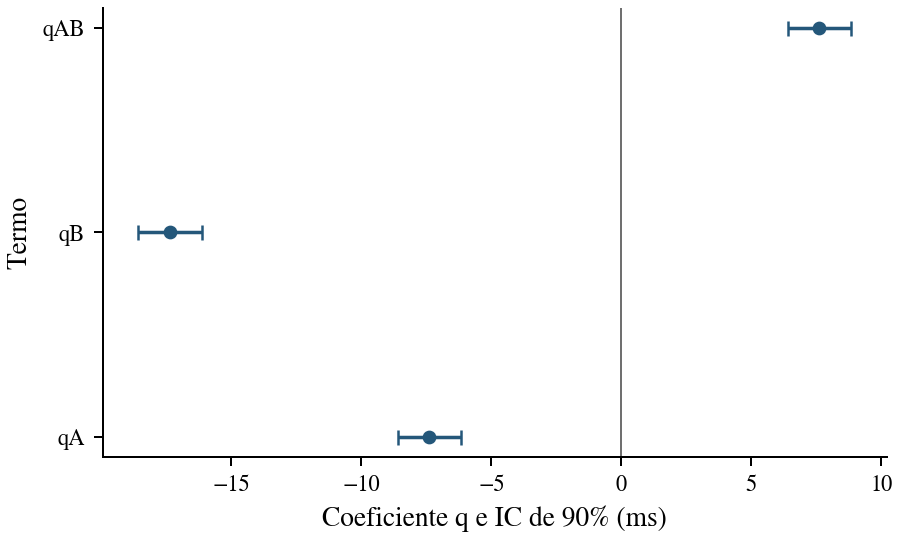

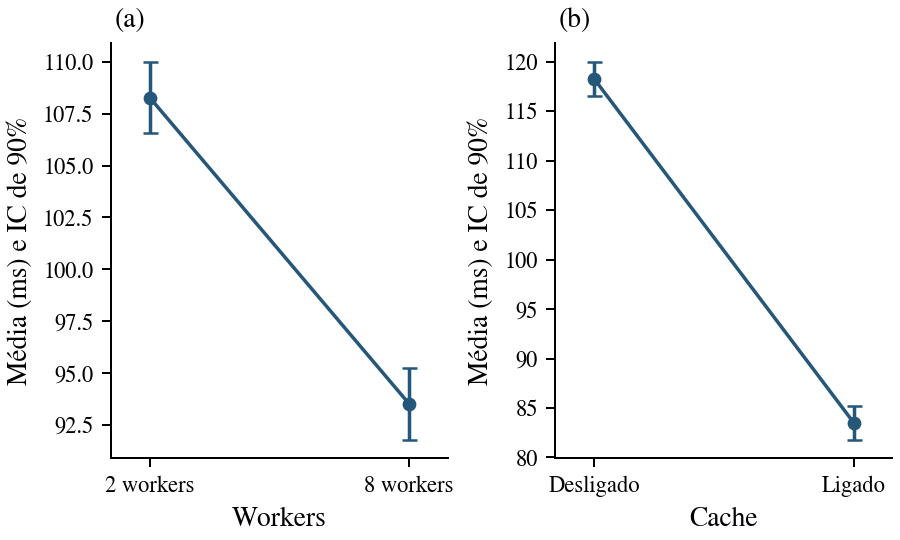

In [9]:
graficos_efeitos(res, '02_efeitos')
graficos_niveis(res, nomes, niveis_reais, '03_niveis', com_ic=True)


## 10 Interação entre workers e cache

A mudança ao passar de 2 para 8 workers depende do nível codificado $b$ de cache.

$$\Delta_A(b)=2(q_A+bq_{AB}).$$

Com cache desligado, $b=-1$. Com cache ligado, $b=+1$. Linhas com inclinações diferentes mostram que o ganho com workers muda entre essas condições. O teste de AB avalia essa diferença de inclinações.

As barras são intervalos individuais para as médias das combinações. A sobreposição de duas barras não substitui o teste do contraste entre as médias. A recomendação operacional precisa considerar a condição em que o serviço será usado.


Painéis do gráfico. (a) Workers e Cache. (b) Cache e Workers.

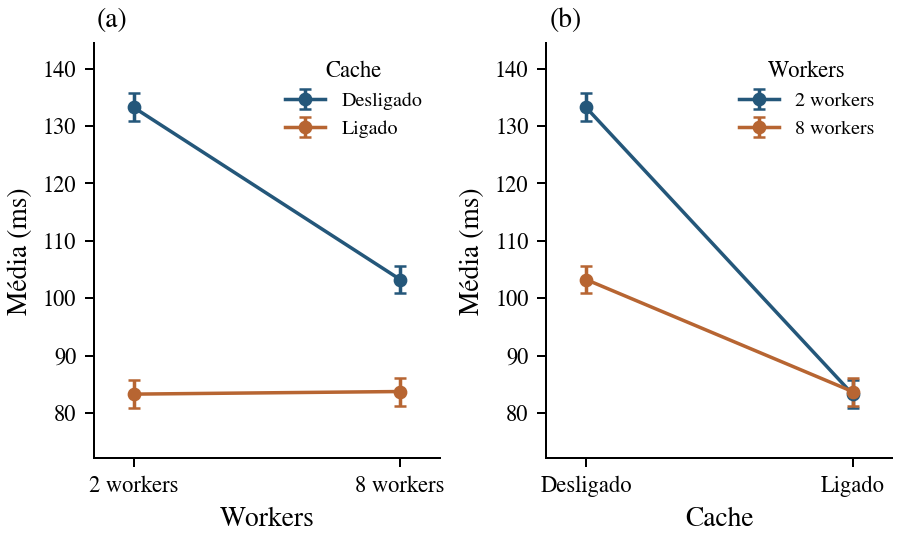

In [10]:
graficos_interacoes(res, nomes, niveis_reais, '04_interacao', com_ic=True)


## 11 Quatro premissas e resíduos

O resíduo é a diferença entre a resposta da sessão e a média estimada para sua combinação. A unidade permanece ms.

$$e_{ij}=y_{ij}-\widehat y_i.$$

O modelo completo reproduz as quatro médias e deixa zero grau de liberdade para falta de ajuste entre elas. O centro residual de cada combinação é zero por construção. Isso não verifica curvatura entre os dois níveis nem justifica interpolação para outras configurações.

A forma da média, a variância comum, a independência e a normalidade precisam ser examinadas junto ao protocolo. O painel a mostra resíduos contra ajustados. O painel b compara a dispersão por combinação. O painel c mostra o Q-Q. O painel d preserva a sequência real de execução.


### Condições do modelo

**Forma da resposta média**

O modelo precisa representar as médias nas condições estudadas. O completo reproduz as médias das combinações fatoriais. Isso deixa zero grau de liberdade para testar falta de ajuste entre esses pontos e não demonstra ausência de curvatura entre os níveis. O gráfico de resíduos contra os valores ajustados ajuda a investigar padrões, mas não certifica a forma do modelo.

**Homocedasticidade dos erros**

A variância deve permanecer aproximadamente constante. O teste de Levene centrado na mediana, conhecido como Brown e Forsythe, usa $H_0$ de variâncias iguais entre as combinações. Em $H_A$, pelo menos uma difere. Sua referência F é aproximada. O gráfico por combinação complementa o teste.

**Independência dos erros**

Os erros de sessões distintas não devem apresentar dependência sistemática. A ordem realmente executada é preservada no gráfico temporal. Durbin e Watson compara diferenças entre resíduos sucessivos com sua soma de quadrados. Valores próximos de 2 sugerem pouca associação de primeira ordem, valores menores sugerem associação positiva e maiores sugerem associação negativa. A referência usada para o valor-p simula erros normais independentes com variância comum sob o mesmo desenho. A alternativa procura dependência serial. O protocolo e o gráfico continuam necessários.

**Normalidade dos erros**

O Q-Q compara os quantis dos resíduos com os da normal. Nos testes de Shapiro e Wilk e de Kolmogorov e Smirnov, $H_0$ afirma normalidade dos erros e $H_A$ afirma desvio dessa forma. O segundo usa média e variância estimadas, como na formulação de Lilliefors. Como os resíduos compartilham parâmetros ajustados, os valores-p dos dois testes são calibrados com erros normais e o mesmo ajuste fatorial. Essa referência depende das demais condições do modelo. Durbin e Watson avalia dependência temporal, não normalidade.

Um teste significativo apresenta evidência contra sua hipótese nula. Um resultado não significativo indica evidência insuficiente para rejeitá-la. Nenhum valor-p demonstra que uma condição é verdadeira. A decisão considera os gráficos, a unidade experimental e o protocolo.


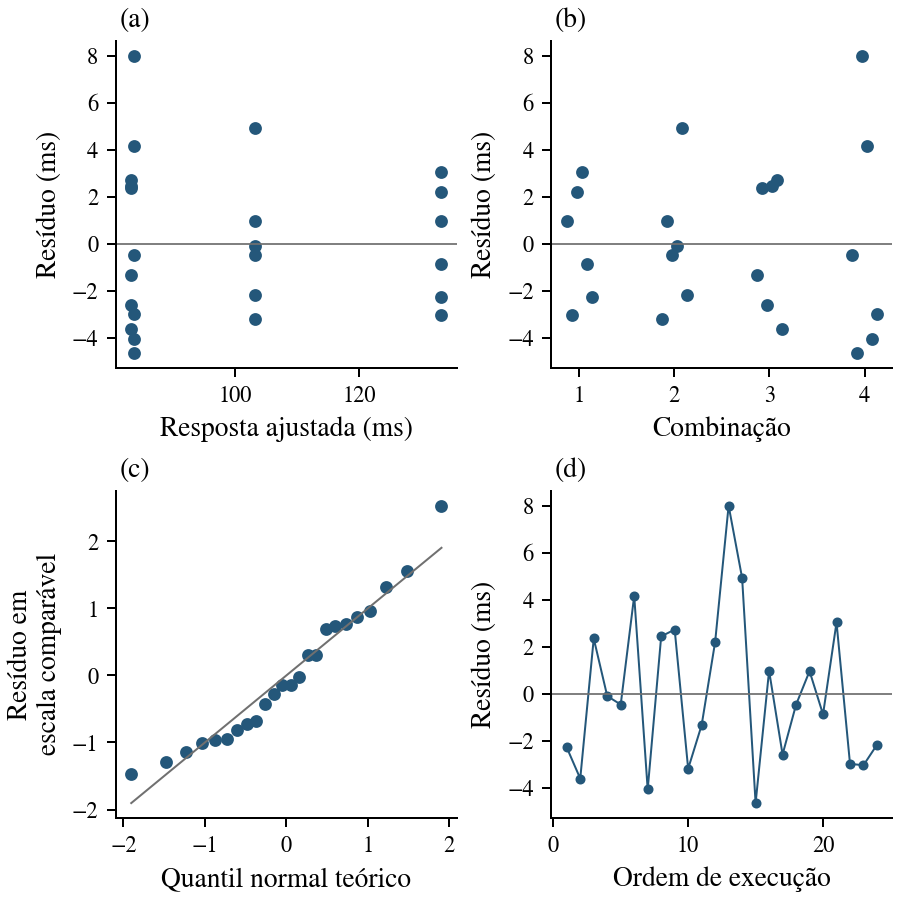

In [11]:
grid_residuos(res, ordem, '05_residuos')


### Padrões que orientam a leitura

| Painel | Padrão ilustrado | O que investigar |
| --- | --- | --- |
| a | Flutuação independente com dispersão estável | Compatibilidade com erros de média zero e variância comum |
| b | Associação serial positiva | Persistência entre sessões vizinhas |
| c | Associação serial negativa | Alternância entre sessões vizinhas |
| d | Senoide | Ciclo no processo de medição |
| e | Cone | Variância que muda com a resposta |
| f | Curva | Estrutura da resposta média ainda não representada |

Os padrões seguintes são esquemas para interpretar gráficos. A ilustração de curvatura pressupõe valores quantitativos adicionais. As quatro combinações deste experimento, com o modelo completo, não permitem testar esse comportamento entre os vértices.


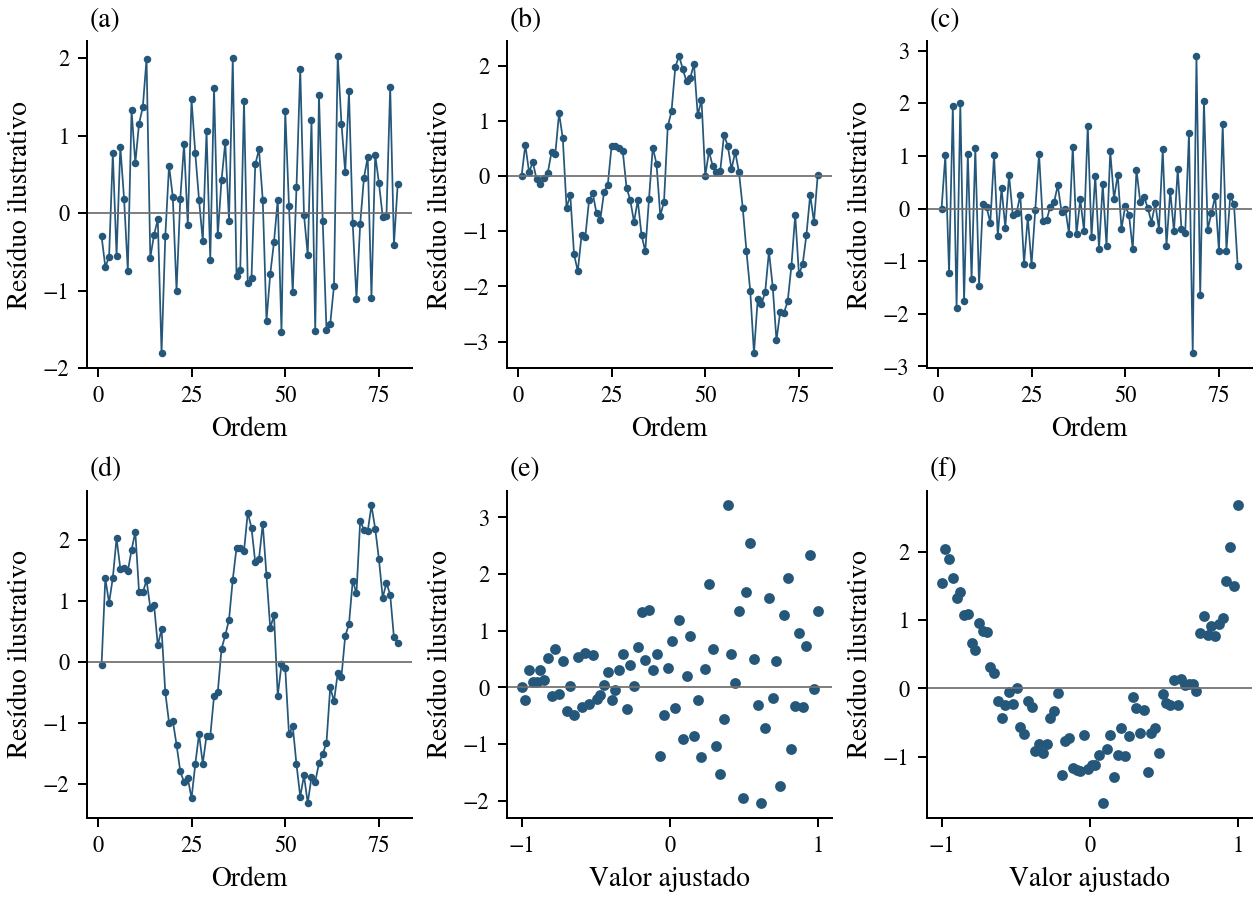

In [12]:
grid_padroes('06_padroes_residuais')


### Testes que acompanham os gráficos

A comparação de variâncias usa Levene centrado na mediana, também conhecido como Brown e Forsythe. Sua referência F é aproximada. Rejeitar a igualdade de variâncias pede investigar a dispersão e as consequências para os intervalos.

A normalidade é examinada com Shapiro e Wilk e com uma estatística de Kolmogorov e Smirnov que usa os parâmetros da normal estimados a partir dos resíduos. Os resíduos compartilham médias estimadas e não formam uma amostra independente. A calibração repete o mesmo ajuste sob erros normais com o planejamento fixo. Ela incorpora a dependência residual e a estimação dos parâmetros. Os dois testes examinam os mesmos resíduos e não são evidências independentes.

O diagnóstico serial usa a sequência sorteada e registrada. Durbin e Watson compara resíduos vizinhos. Sua conclusão se limita à forma de associação temporal avaliada. A ausência de rejeição não prova independência em todas as escalas.

As hipóteses dos diagnósticos são

| Teste | $H_0$ | $H_A$ |
| --- | --- | --- |
| Brown e Forsythe | As quatro variâncias são iguais | Pelo menos uma variância difere |
| Shapiro e Wilk | Os erros seguem a referência normal | A forma dos erros se afasta da normal |
| Kolmogorov e Smirnov calibrado | Os erros seguem a referência normal com parâmetros estimados | A forma dos erros se afasta dessa referência |
| Durbin e Watson calibrado | Os erros são independentes na referência normal adotada | Há associação serial incompatível com essa referência |

As hipóteses sobre a forma normal mantêm as demais condições do modelo. Cada valor-p é lido na referência correspondente. A saída apresenta o valor-p e a decisão no nível definido. Um resultado sem significância fornece evidência limitada com seis replicações por combinação. A leitura final continua vinculada ao mecanismo, aos gráficos e à forma de coleta.


In [13]:
resultado_diagnosticos = diagnosticos(res, ordem, '07_diagnosticos')


,Diagnóstico,Estatística,Valor-p,Referência
0,Brown e Forsythe,1.1783,0.343,F aproximada
1,Shapiro e Wilk,0.95241,0.3036,Normal no mesmo desenho
2,Kolmogorov e Smirnov,0.12411,0.425,Normal no mesmo desenho
3,Durbin e Watson,1.9507,0.8692,Normal independente no mesmo desenho


**Homocedasticidade**

Não é significativo porque o valor-p 0.343 é maior que 0.10. Não há evidência suficiente contra a igualdade das variâncias.

**Shapiro e Wilk**

Não é significativo porque o valor-p 0.3036 é maior que 0.10. Não há evidência suficiente contra a normalidade sob a referência adotada.

**Kolmogorov e Smirnov**

Não é significativo porque o valor-p 0.425 é maior que 0.10. Não há evidência suficiente contra a normalidade sob a referência adotada.

**Durbin e Watson**

Não é significativo porque o valor-p 0.8692 é maior que 0.10. Não há evidência suficiente de dependência serial nessa comparação. O protocolo continua necessário.

## 12 Leitura dos resultados no contexto do serviço

O sinal de cada coeficiente mostra a direção de um contraste. Sua soma de quadrados mostra a parcela da variação observada. O intervalo e o valor-p mostram a incerteza da estimativa sob as premissas adotadas. A interação informa quando a comparação marginal precisa ser desdobrada por condição.

No contexto do serviço, a comparação de workers deve acompanhar o estado do cache. Uma diferença pequena diante da meta de 5 ms pode ter pouco interesse operacional mesmo quando o teste contra zero é significativo.

A análise se refere aos níveis, à carga, ao hardware e ao protocolo utilizados.


## Referências

- Aula de Projeto e Análise de Experimentos. Material da disciplina.
- Raj Jain. *The Art of Computer Systems Performance Analysis*. Wiley, 1991. Capítulos 16 a 18. [Material do autor](https://www.cse.wustl.edu/~jain/books/perf_sli.htm) e [errata](https://www.cse.wustl.edu/~jain/books/ftp/errors_all.pdf).
- Douglas C. Montgomery. *Design and Analysis of Experiments*. Planejamento fatorial, análise de variância e adequação de modelos. [Sumário da editora](https://bcs.wiley.com/he-bcs/Books?action=contents&bcsId=11447&itemId=1119492440).
- NIST/SEMATECH. [Delineamentos fatoriais de dois níveis](https://www.itl.nist.gov/div898/handbook/pri/section3/pri3331.htm), [intervalos para a média](https://www.itl.nist.gov/div898/handbook/eda/section3/eda352.htm) e [Levene](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35a.htm).
- SciPy. [Shapiro e Wilk](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html). Statsmodels. [Lilliefors](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.lilliefors.html) e [Durbin e Watson](https://www.statsmodels.org/stable/generated/statsmodels.stats.stattools.durbin_watson.html). SciPy. [Calibração Monte Carlo com parâmetros estimados](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.goodness_of_fit.html). Referências de implementação dos diagnósticos.
